In [34]:
import pandas as pd
import seaborn as sns

red_wine = pd.read_csv("winequality-red.csv")
red_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [35]:
red_wine.shape # (rows, columns)
red_wine = red_wine.drop_duplicates()
red_wine = red_wine.dropna()
red_wine.shape

(1359, 12)

In [41]:
red_wine.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1359.0,8.310596,1.736990,4.60000,7.1000,7.9000,9.20000,15.90000
volatile acidity,1359.0,0.529478,0.183031,0.12000,0.3900,0.5200,0.64000,1.58000
citric acid,1359.0,0.272333,0.195537,0.00000,0.0900,0.2600,0.43000,1.00000
residual sugar,1359.0,2.523400,1.352314,0.90000,1.9000,2.2000,2.60000,15.50000
chlorides,1359.0,0.088124,0.049377,0.01200,0.0700,0.0790,0.09100,0.61100
free sulfur dioxide,1359.0,15.893304,10.447270,1.00000,7.0000,14.0000,21.00000,72.00000
total sulfur dioxide,1359.0,46.825975,33.408946,6.00000,22.0000,38.0000,63.00000,289.00000
density,1359.0,0.996709,0.001869,0.99007,0.9956,0.9967,0.99782,1.00369
pH,1359.0,3.309787,0.155036,2.74000,3.2100,3.3100,3.40000,4.01000
sulphates,1359.0,0.658705,0.170667,0.33000,0.5500,0.6200,0.73000,2.00000


In [43]:
red_wine['quality'].value_counts().sort_index()

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64

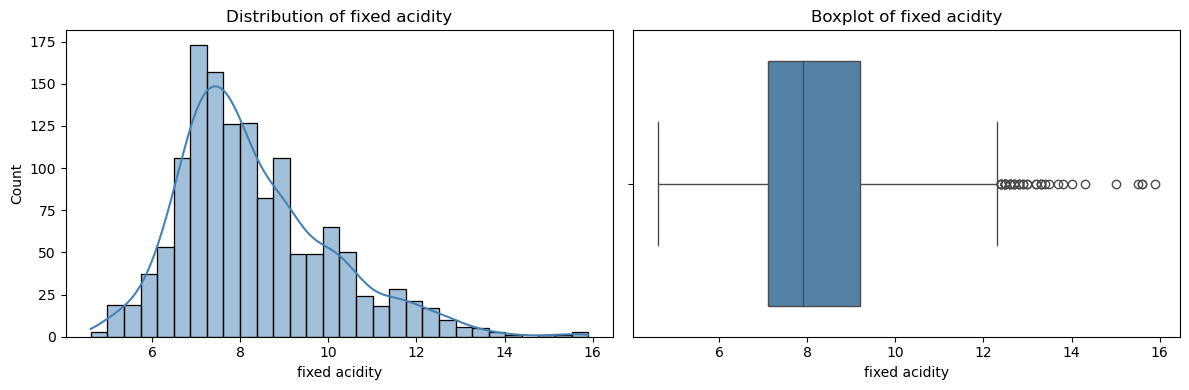

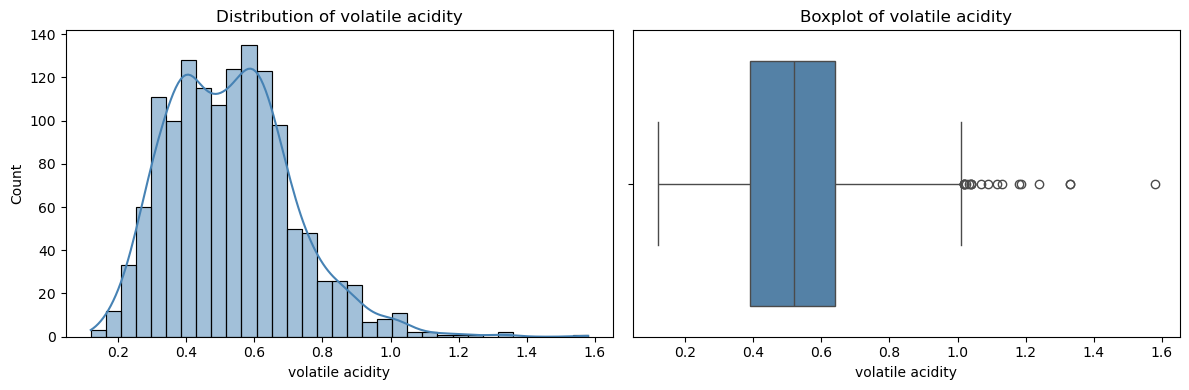

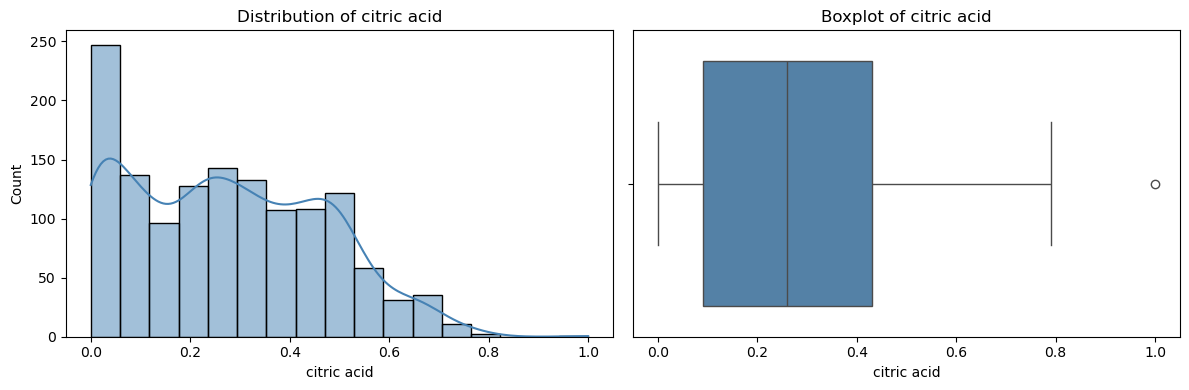

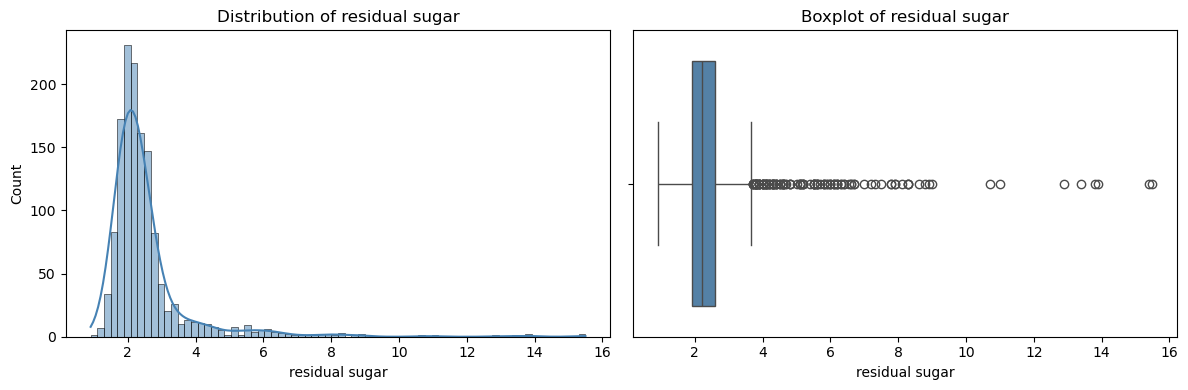

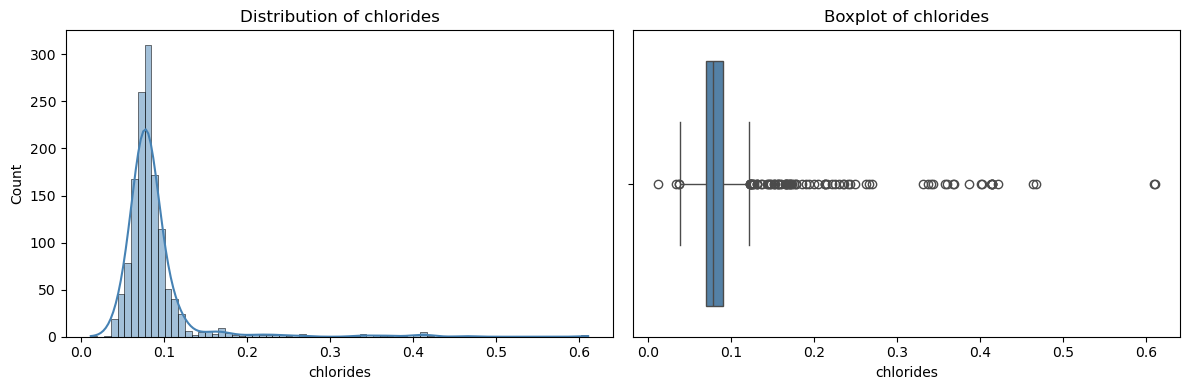

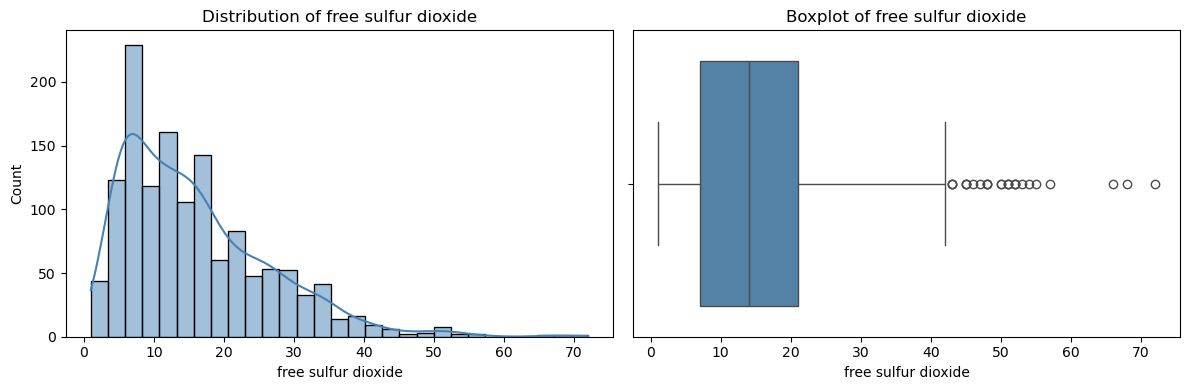

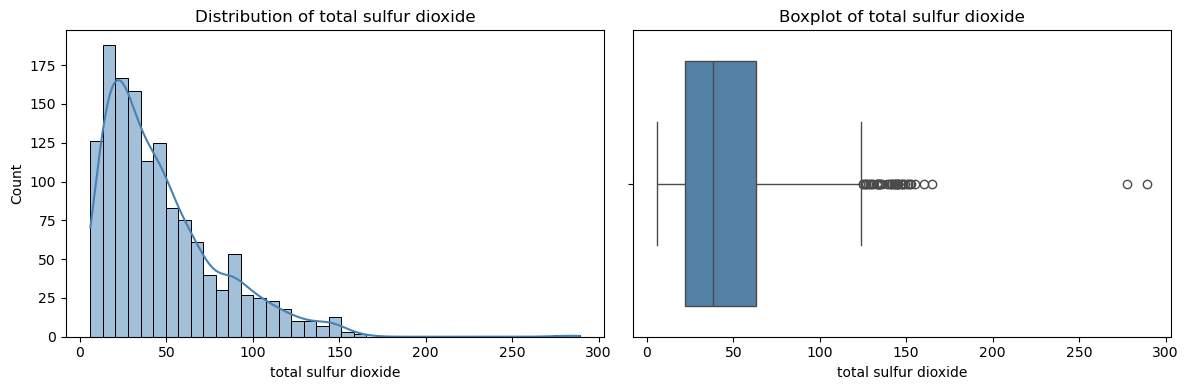

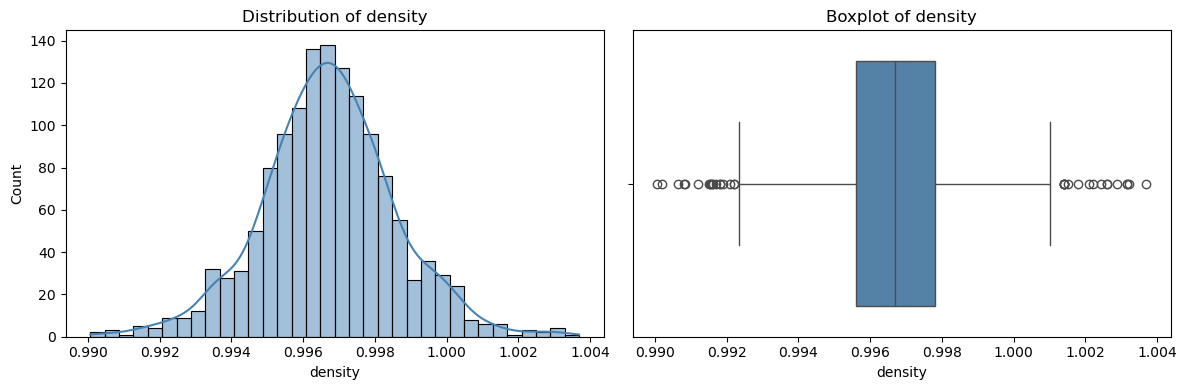

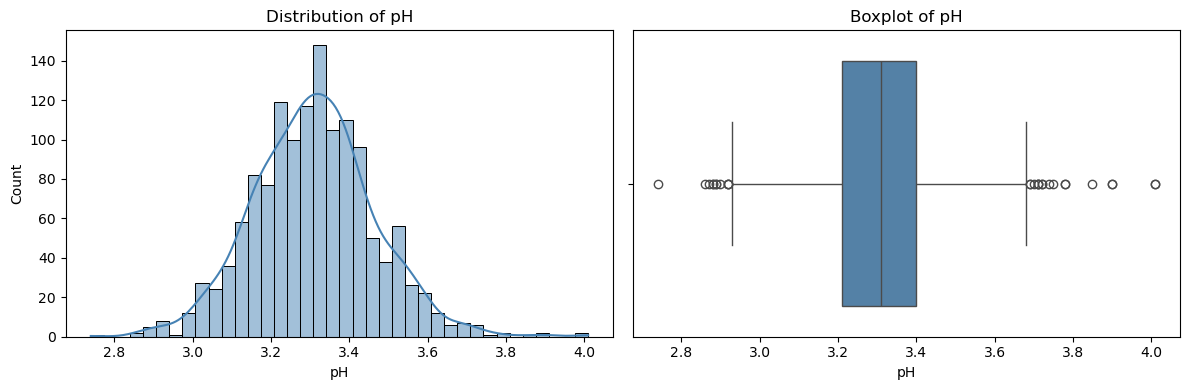

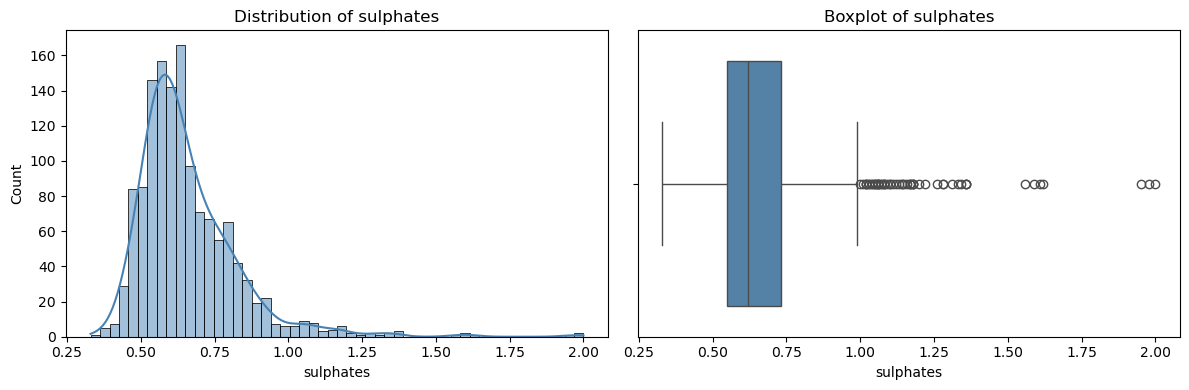

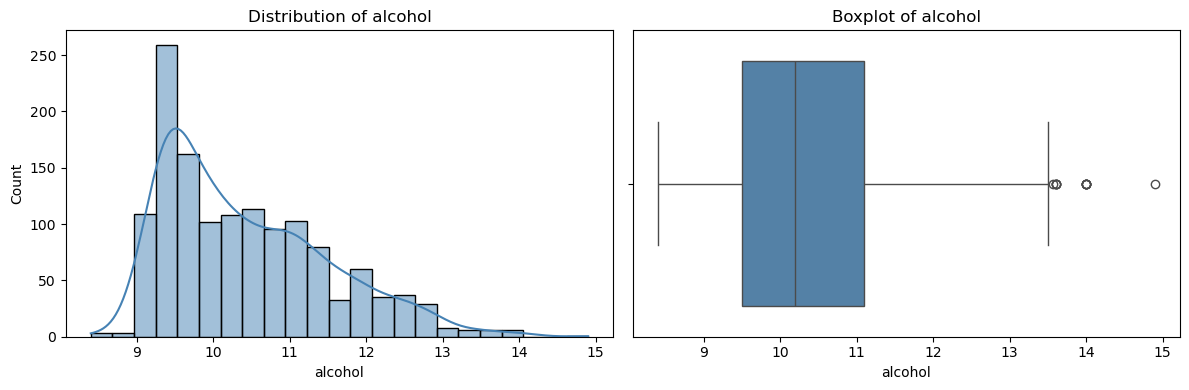

In [37]:
numerical_cols = red_wine.columns.drop('quality')

for col in numerical_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(red_wine[col], kde=True, ax=axes[0], color="steelblue")
    sns.boxplot(x=red_wine[col], ax=axes[1], color="steelblue")
    axes[0].set_title(f"Distribution of {col}")
    axes[1].set_title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

In [46]:
print("pH within [0, 14]:", red_wine['pH'].between(0, 14).all())
print("quality within [3, 8]:", red_wine['quality'].between(3, 8).all())
print("All measurement columns positive:", (red_wine[numerical_cols] > 0).all().all())

pH within [0, 14]: True
quality within [3, 8]: True
All measurement columns positive: False


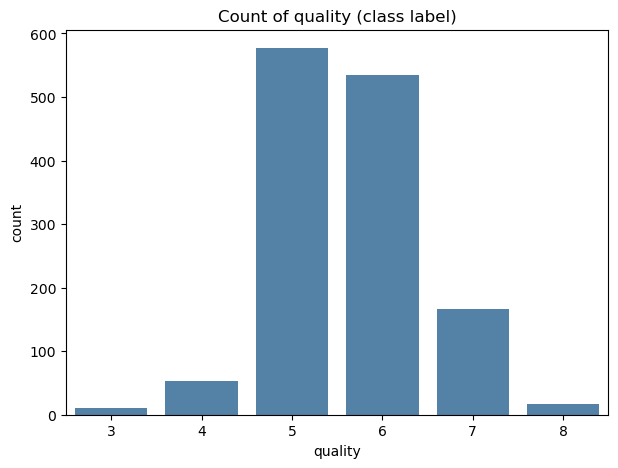

In [48]:
plt.figure(figsize=(7, 5))
sns.countplot(x=red_wine['quality'], order=sorted(red_wine['quality'].unique()), color="steelblue")
plt.title("Count of quality (class label)")
plt.show()

In [50]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = red_wine.drop(columns=['quality'])
y = red_wine['quality'].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

input_shape = (X_train.shape[1],)

In [52]:
from tensorflow import keras
from tensorflow.keras import layers

# YOUR CODE HERE
model = keras.Sequential([
    layers.Input(shape=input_shape),
    layers.Dense(64,activation='relu',name ='hidden_layer_1'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(64,activation='relu',name ='hidden_layer_2'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu",name ='hidden_layer_3'),
    layers.Dense(1,name ='output_layer'),
])


In [53]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_3 (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,553 (29.50 KB)

 Trainable params: 7,297 (28.50 KB)

 Non-trainable params: 256 (1.00 KB)

In [54]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error",  # MSE for regression
    metrics=["mae"],  # Mean Absolute Error
)
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,  # Wait 15 epochs before stopping
    restore_best_weights=True,
)
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    batch_size=64,
    epochs=100,
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 29.4504 - mae: 5.2463 - val_loss: 30.5417 - val_mae: 5.4679
Epoch 2/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 19.7564 - mae: 4.2594 - val_loss: 26.5133 - val_mae: 5.0899
Epoch 3/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 12.4488 - mae: 3.2736 - val_loss: 22.4039 - val_mae: 4.6669
Epoch 4/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 6.7695 - mae: 2.2881 - val_loss: 18.2377 - val_mae: 4.1929
Epoch 5/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 3.8576 - mae: 1.6263 - val_loss: 14.6827 - val_mae: 3.7414
Epoch 6/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 2.5661 - mae: 1.3043 - val_loss: 11.9821 - val_mae: 3.3638
Epoch 7/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2.0580 - mae: 1.1551 - val_loss: 9.7931 - val_mae: 3.0248
Epoch 8/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.8281 - mae: 1.0749 - val_loss: 8.1082 - val_mae: 2.7399
Epoch 9/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - l


Test Mean Absolute Error: 0.532 quality points
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
Actual Quality: 5 | Predicted: 5.07
Actual Quality: 6 | Predicted: 6.17
Actual Quality: 7 | Predicted: 6.97
Actual Quality: 5 | Predicted: 4.88
Actual Quality: 4 | Predicted: 5.47


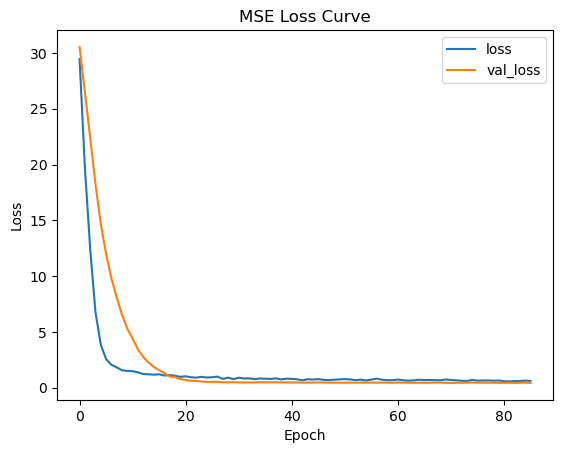

In [55]:
test_loss, test_mae = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Mean Absolute Error: {test_mae:.3f} quality points")
# Make predictions on first 5 test samples
predictions = model.predict(X_test[:5])
for actual, pred in zip(y_test[:5], predictions.flatten()):
    print(f"Actual Quality: {actual} | Predicted: {pred:.2f}")
# ==========================================
# 7. (Optional) Plot Training Curves
# ==========================================
history_df = pd.DataFrame(history.history)
history_df[["loss", "val_loss"]].plot(title="MSE Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()